# UAV Time Series Descriptive Mining Analysis

## Overview
This notebook performs comprehensive descriptive mining on UAV flight time series data to uncover patterns, anomalies, and hidden insights.

**What "descriptive mining" means here:** we are not building a predictive model. The goal is to characterize the data well enough to (a) trust its quality, (b) understand how control errors and faults behave individually and together, and (c) surface structure (clusters, temporal dependence) that would justify a modeling effort later. Every section below states *why* that step matters before running it, so the notebook doubles as a reasoning trail, not just a set of plots.

## Data Description
The dataset contains UAV flight data with the following columns:
- **bag**: Bag file identifier
- **timestamp_ns**: Nanosecond timestamp
- **Control Commands**: airspeed_cmd, roll_cmd, pitch_cmd, yaw_cmd
- **Measurements**: airspeed_meas, roll_meas, pitch_meas, yaw_meas
- **Errors**: airspeed_error, roll_error, pitch_error, yaw_error
- **Velocity**: vel_x, vel_y, vel_z
- **IMU**: imu_x, imu_y, imu_z
- **Fault Flags**: engine_fault, aileron_fault, elevator_fault, rudder_fault
- **dataset**: Data split identifier


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

In [2]:
# Load the data
print("Loading UAV time series data...")
df = pd.read_csv('../descriptive/uav_timeseries.csv')
print(f"Dataset shape: {df.shape}")
print(f"Number of columns: {len(df.columns)}")
print("\nFirst few rows:")
df.head()

Loading UAV time series data...
Dataset shape: (180812, 25)
Number of columns: 25

First few rows:


,bag,timestamp_ns,airspeed_cmd,airspeed_meas,airspeed_error,roll_cmd,roll_meas,roll_error,pitch_cmd,pitch_meas,...,vel_y,vel_z,imu_x,imu_y,imu_z,engine_fault,aileron_fault,elevator_fault,rudder_fault,dataset
0,carbonZ_2018-07-18-12-10-11.bag,1531930511391720552,15.0,0.0,15.0,0.100000,2.954323,-2.854323,-2.55,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
1,carbonZ_2018-07-18-12-10-11.bag,1531930511452938696,15.0,0.0,15.0,30.340000,2.954323,27.385678,-1.31,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
2,carbonZ_2018-07-18-12-10-11.bag,1531930511484229416,15.0,0.0,15.0,30.320000,2.954323,27.365677,-1.31,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
3,carbonZ_2018-07-18-12-10-11.bag,1531930511543160328,15.0,0.0,15.0,30.299999,2.954323,27.345677,-1.31,8.487809,...,-0.279165,4.326915,-0.0748,-0.023208,-0.996428,0,0,0,0,test
4,carbonZ_2018-07-18-12-10-11.bag,1531930511568218792,15.0,0.0,15.0,31.920000,2.954323,28.965677,-5.60,8.487809,...,-0.279165,4.326915,-0.0748,-0.023208,-0.996428,0,0,0,0,test


In [3]:
# Task 2: Analyze data types and basic statistics
print("=== DATA TYPE ANALYSIS ===\n")

# Data types
print("Data Types:")
print(df.dtypes)

# Check for missing values
print("\nMissing Values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found")

# Basic statistics for numerical columns
print("\nBasic Statistics for Numerical Columns:")
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical columns: {len(num_cols)}")
print(df[num_cols].describe().T)

=== DATA TYPE ANALYSIS ===

Data Types:
bag                   str
timestamp_ns        int64
airspeed_cmd      float64
airspeed_meas     float64
airspeed_error    float64
roll_cmd          float64
roll_meas         float64
roll_error        float64
pitch_cmd         float64
pitch_meas        float64
pitch_error       float64
yaw_cmd           float64
yaw_meas          float64
yaw_error         float64
vel_x             float64
vel_y             float64
vel_z             float64
imu_x             float64
imu_y             float64
imu_z             float64
engine_fault        int64
aileron_fault       int64
elevator_fault      int64
rudder_fault        int64
dataset               str
dtype: object

Missing Values:
pitch_cmd        31
pitch_meas       31
pitch_error      31
yaw_cmd          29
yaw_meas         29
yaw_error        29
vel_x          8332
vel_y          8332
vel_z          8332
dtype: int64

Basic Statistics for Numerical Columns:
Numerical columns: 23
                   coun

In [4]:
# Task 3: Generate summary statistics and distributions
print("=== SUMMARY STATISTICS AND DISTRIBUTIONS ===\n")

# Calculate additional statistics
print("Skewness and Kurtosis Analysis:")
skew_kurt = pd.DataFrame({
    'Skewness': df[num_cols].skew(),
    'Kurtosis': df[num_cols].kurtosis()
})
print(skew_kurt.sort_values('Skewness', ascending=False).head(10))

# Identify extreme skewness
print("\nColumns with Extreme Skewness (|skew| > 2):")
extreme_skew = skew_kurt[abs(skew_kurt['Skewness']) > 2]
print(extreme_skew)

# Categorical column analysis
print("\nCategorical Column Analysis:")
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    print(f"\n{col}:")
    print(f"  Unique values: {df[col].nunique()}")
    print(f"  Top 5 values:\n{df[col].value_counts().head()}")

=== SUMMARY STATISTICS AND DISTRIBUTIONS ===

Skewness and Kurtosis Analysis:
                 Skewness    Kurtosis
elevator_fault  19.903582  394.156932
rudder_fault    14.139886  207.511874
aileron_fault    5.975152   37.312939
engine_fault     2.647485    5.009235
pitch_meas       2.498926   25.637263
airspeed_meas    1.446754    0.290649
imu_z            1.364273    0.534875
yaw_meas         0.706741   -0.798637
roll_cmd         0.381397   -0.525478
roll_meas        0.294068    1.066185

Columns with Extreme Skewness (|skew| > 2):
                 Skewness    Kurtosis
pitch_meas       2.498926   25.637263
pitch_error     -2.582080   24.520516
engine_fault     2.647485    5.009235
aileron_fault    5.975152   37.312939
elevator_fault  19.903582  394.156932
rudder_fault    14.139886  207.511874

Categorical Column Analysis:

bag:
  Unique values: 36
  Top 5 values:
bag
carbonZ_2018-09-11-14-42-06.bag    24329
carbonZ_2018-10-05-14-34-20.bag    14494
carbonZ_2018-07-30-16-39-00.bag    

In [5]:
# 1. Calculate rate of change (First Derivative)
df['yaw_error_rate'] = df['yaw_error'].diff().abs()

# 2. Calculate rolling variance (Noise/Instability Spike)
df['roll_error_rolling_std'] = df['roll_error'].rolling(window=10).std()

# 3. Define a "Sudden Drop" trigger threshold
# Example: Rate of change > 5x the normal baseline average
rate_threshold = df['yaw_error_rate'].mean() + (5 * df['yaw_error_rate'].std())

# Flag the exact sample indices where sudden drops occur
df['sudden_drop_detected'] = df['yaw_error_rate'] > rate_threshold

print(f"Sudden drop events detected at index locations:")
print(df[df['sudden_drop_detected']].index.tolist())

Sudden drop events detected at index locations:
[1, 10, 466, 511, 571, 593, 1646, 1677, 1739, 1780, 2806, 2848, 4046, 5632, 5634, 6247, 6267, 6316, 6325, 6342, 6362, 7599, 7633, 8592, 8643, 8647, 8839, 9324, 9334, 10590, 10625, 11294, 11848, 11865, 12066, 12075, 12722, 12744, 12764, 12797, 12822, 12859, 12877, 12885, 14199, 14223, 14240, 14282, 14347, 14377, 14703, 14709, 14912, 15309, 15345, 15550, 15628, 16129, 16759, 16818, 16841, 16843, 18217, 18237, 18282, 18318, 18367, 18421, 18761, 18764, 19505, 19607, 19629, 19706, 21284, 21324, 21463, 21653, 21669, 22438, 22488, 24105, 24126, 24261, 26988, 27597, 27609, 28864, 28930, 28933, 29460, 29514, 29534, 29547, 29587, 29589, 31153, 31213, 31236, 31249, 31323, 31402, 31449, 31595, 31709, 32192, 32221, 33560, 33584, 33612, 33661, 33680, 33757, 33810, 33811, 33866, 33867, 35337, 35500, 35515, 35704, 35900, 36609, 37005, 37025, 37102, 37116, 37133, 37140, 37147, 37160, 37174, 37186, 38318, 38336, 39117, 39462, 39962, 39973, 40452, 40478, 41

### Why visualize distributions, correlations, and a time series sample here?

Numbers alone (means, skew) can hide shape: bimodal distributions, sharp anomaly spikes, or clipped/saturated sensor values only show up visually. This section combines four complementary views on purpose:
- **Histograms** reveal shape (is error roughly Gaussian, or heavy-tailed?).
- **Fault bar chart** gives a quick sense of class imbalance (faults are rare events).
- **Correlation heatmap** checks whether errors move together (a single root cause) or independently.
- **Time series + boxplot** put the same data in "when did it happen" and "how spread out is it" terms.

Together they build intuition before we do anything statistical with these columns.

=== VISUALIZATIONS FOR PATTERNS AND ANOMALIES ===



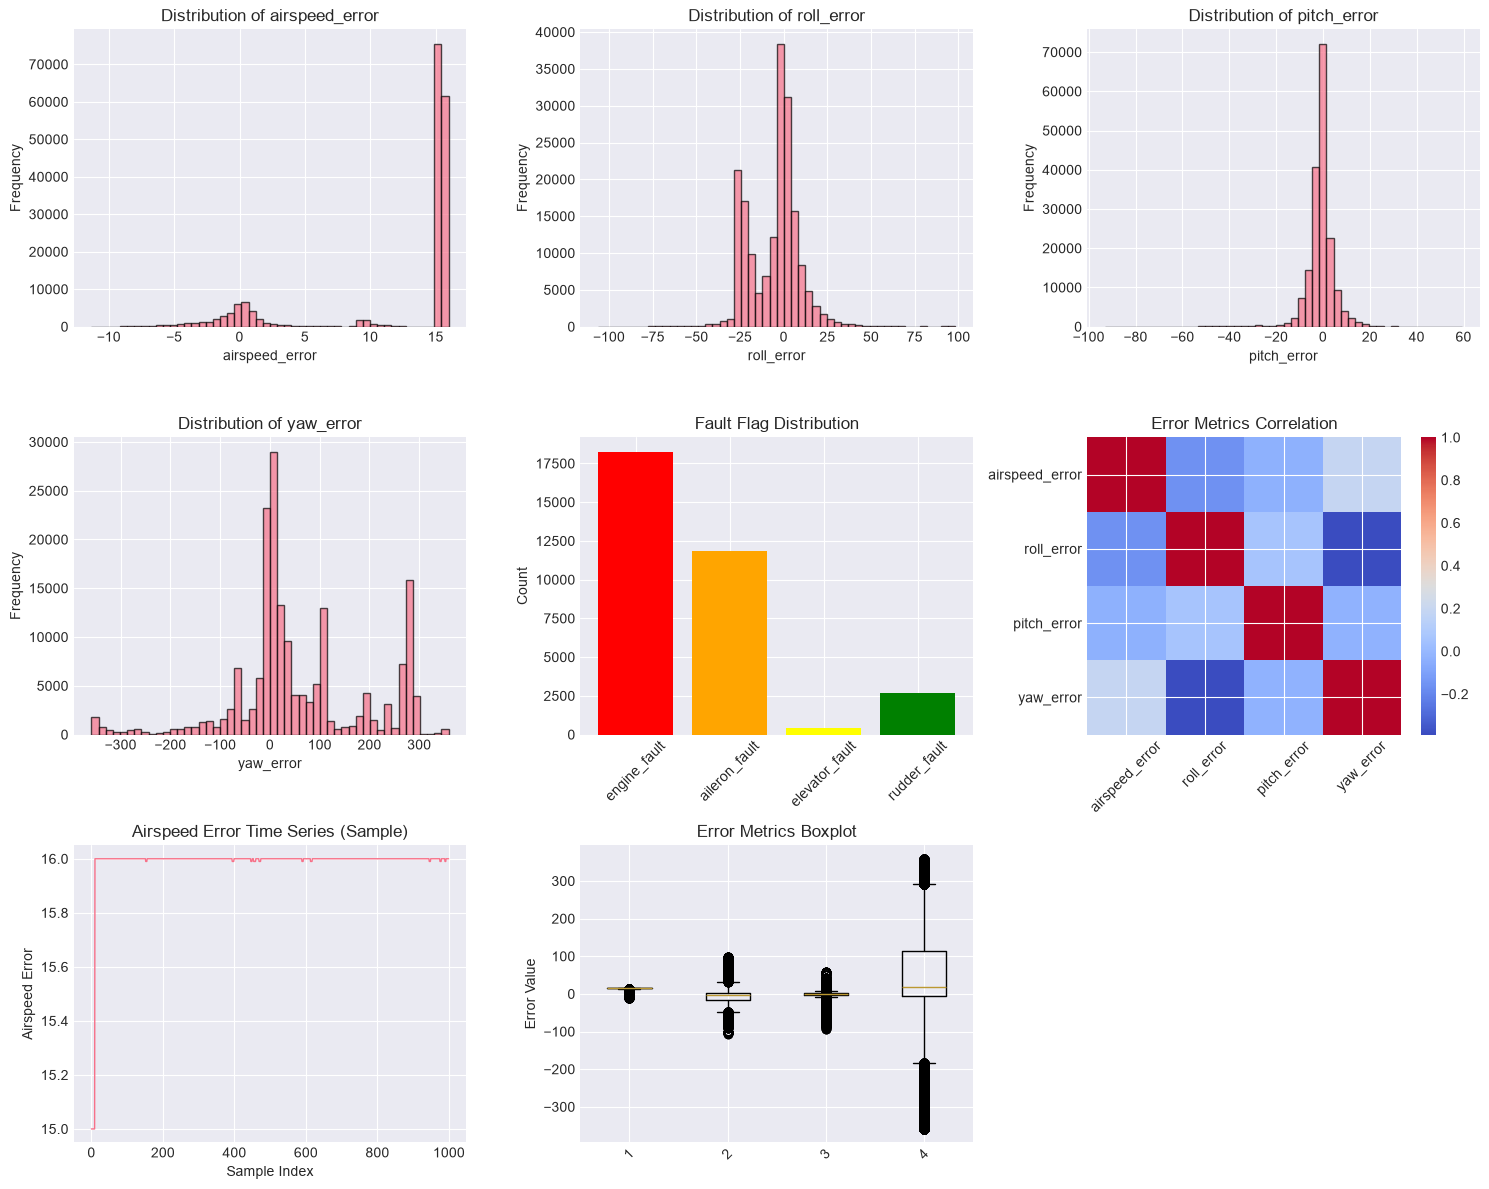

In [6]:
# Task 4: Create visualizations for patterns and anomalies
print("=== VISUALIZATIONS FOR PATTERNS AND ANOMALIES ===\n")

# Create figure for distributions
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

# Plot distributions of key error metrics
error_cols = ['airspeed_error', 'roll_error', 'pitch_error', 'yaw_error']
for i, col in enumerate(error_cols[:4]):
    axes[i].hist(df[col].dropna(), bins=50, alpha=0.7, edgecolor='black')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    
# Plot fault flags distribution
fault_cols = ['engine_fault', 'aileron_fault', 'elevator_fault', 'rudder_fault']
fault_counts = df[fault_cols].sum()

axes[4].bar(fault_counts.index, fault_counts.values, color=['red', 'orange', 'yellow', 'green'])
axes[4].set_title('Fault Flag Distribution')
axes[4].set_ylabel('Count')
axes[4].tick_params(axis='x', rotation=45)

# Plot correlation heatmap for error metrics
correlation_matrix = df[error_cols].corr()
im = axes[5].imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
axes[5].set_title('Error Metrics Correlation')
axes[5].set_xticks(range(len(error_cols)))
axes[5].set_xticklabels(error_cols, rotation=45)
axes[5].set_yticks(range(len(error_cols)))
axes[5].set_yticklabels(error_cols)
plt.colorbar(im, ax=axes[5])

# Plot time series of airspeed error
sample_data = df.head(1000)  # Sample for visualization
axes[6].plot(sample_data.index, sample_data['airspeed_error'], linewidth=1)
axes[6].set_title('Airspeed Error Time Series (Sample)')
axes[6].set_xlabel('Sample Index')
axes[6].set_ylabel('Airspeed Error')

# Plot boxplot of errors
axes[7].boxplot([df[col].dropna() for col in error_cols], label=error_cols)
axes[7].set_title('Error Metrics Boxplot')
axes[7].set_ylabel('Error Value')
axes[7].tick_params(axis='x', rotation=45)

# Remove empty subplot
axes[8].axis('off')

plt.tight_layout()
plt.show()

=== COMMAND VS. MEASURED TRACKING ===



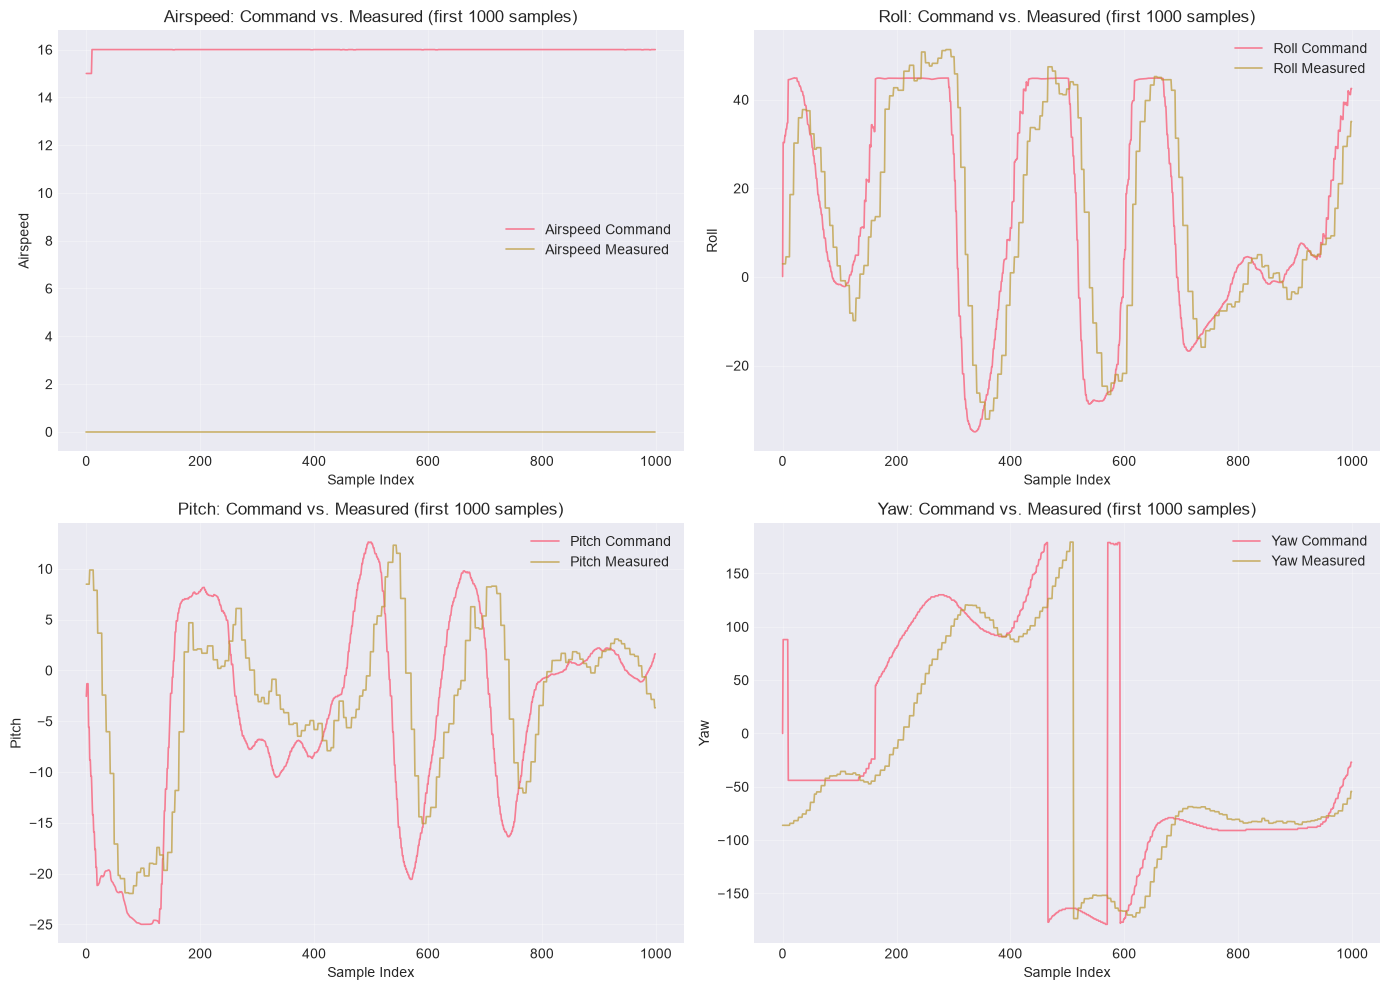

Interpretation guide:
  - Consistent gap between the two lines -> steady-state bias in the controller.
  - Measured line lagging behind command -> tracking delay / slow response.
  - Measured line oscillating around command -> possible instability or noisy sensor.


In [7]:
# Extra visualization: Command vs. Measured (control-tracking performance)
# WHY: error columns (airspeed_error, roll_error, ...) are already a *derived* signal.
# Plotting commanded vs. measured directly shows *how* the controller is failing to track
# (lag? offset bias? oscillation?) in a way a single error number cannot.
print("=== COMMAND VS. MEASURED TRACKING ===\n")

track_pairs = [
    ('airspeed_cmd', 'airspeed_meas', 'Airspeed'),
    ('roll_cmd', 'roll_meas', 'Roll'),
    ('pitch_cmd', 'pitch_meas', 'Pitch'),
    ('yaw_cmd', 'yaw_meas', 'Yaw'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

sample_n = 1000
for i, (cmd_col, meas_col, label) in enumerate(track_pairs):
    axes[i].plot(df[cmd_col].values[:sample_n], label=f'{label} Command', linewidth=1.2, alpha=0.9)
    axes[i].plot(df[meas_col].values[:sample_n], label=f'{label} Measured', linewidth=1.2, alpha=0.7)
    axes[i].set_title(f'{label}: Command vs. Measured (first {sample_n} samples)')
    axes[i].set_xlabel('Sample Index')
    axes[i].set_ylabel(label)
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Interpretation guide:")
print("  - Consistent gap between the two lines -> steady-state bias in the controller.")
print("  - Measured line lagging behind command -> tracking delay / slow response.")
print("  - Measured line oscillating around command -> possible instability or noisy sensor.")


=== ERROR DISTRIBUTION SHAPE: FAULT VS. NO FAULT (VIOLIN PLOTS) ===



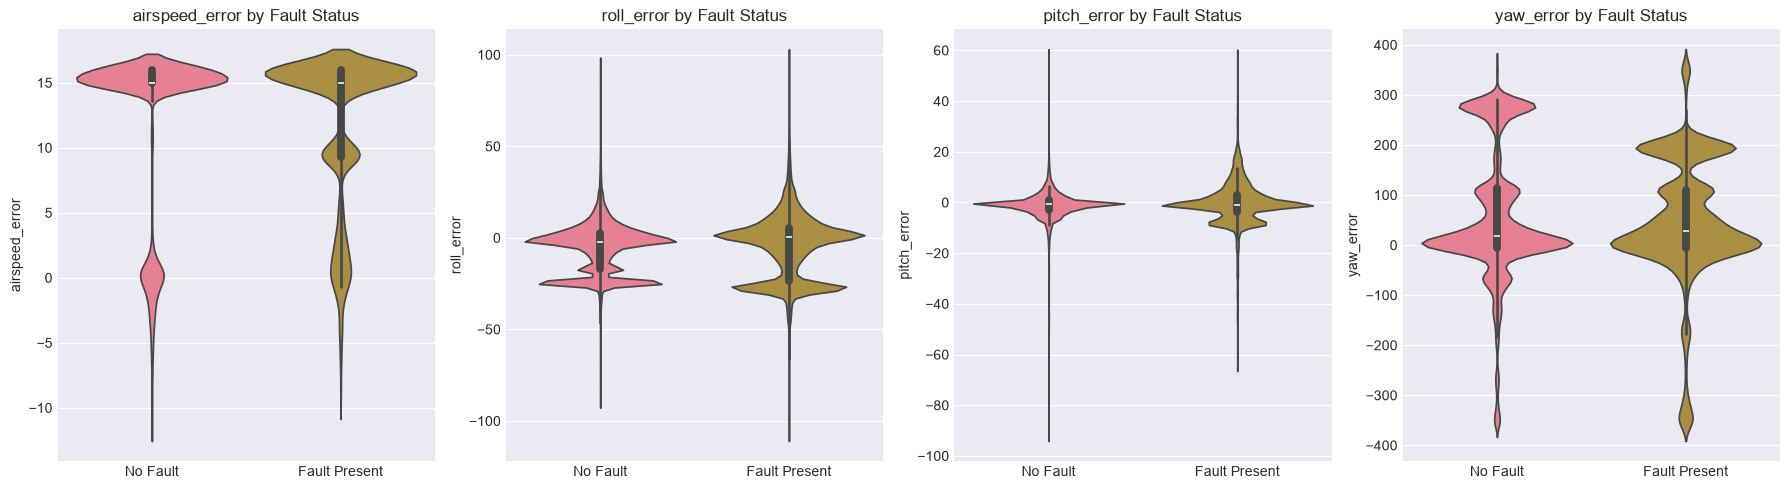

In [8]:
# Extra visualization: Violin plots of error distributions, split by fault presence
# WHY: the histogram overlay earlier (fault vs no-fault) hides distribution shape once
# bars overlap. A violin plot shows the full density shape for each group side by side,
# making it easy to see whether faults shift the *mean*, widen the *spread*, or create a
# second mode (bimodal) in the error distribution.
print("=== ERROR DISTRIBUTION SHAPE: FAULT VS. NO FAULT (VIOLIN PLOTS) ===\n")

df['any_fault'] = (df[fault_cols].sum(axis=1) > 0).map({True: 'Fault Present', False: 'No Fault'})

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(error_cols):
    sns.violinplot(data=df, x='any_fault', y=col, ax=axes[i], hue='any_fault', legend=False)
    axes[i].set_title(f'{col} by Fault Status')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()


### Why analyze fault flags and their associations?

Fault flags are the closest thing this dataset has to a "ground truth" label for problems. Before building any predictive or maintenance logic on top of them, we need to know:
- How rare are they (class imbalance affects any future model)?
- Do multiple faults tend to happen **together** (suggesting a shared root cause, e.g. a power issue affecting several actuators) or independently?
- Do faults actually coincide with larger control errors (validating that the flags are meaningful) or not (suggesting the flag and the error signal disagree, which would need investigation)?

=== FAULT FLAG ANALYSIS ===

Fault Flag Statistics:
                Total Faults  Percentage
engine_fault           18270       10.10
aileron_fault          11856        6.56
elevator_fault           453        0.25
rudder_fault            2693        1.49

Simultaneous Fault Analysis:
total_faults
0    154350
1     21766
2      2582
3      2114
Name: count, dtype: int64

Correlation Between Faults and Error Metrics:
Mean Error Difference (Fault=1 vs Fault=0):
                airspeed_error  roll_error  pitch_error  yaw_error
engine_fault           -2.4604     -1.7356       0.9514    13.9359
aileron_fault           4.2393      5.8944       0.4726   -60.2076
elevator_fault          4.0890      8.4414       0.4099   -51.5583
rudder_fault            4.1072      7.1019       1.2385   -82.4801


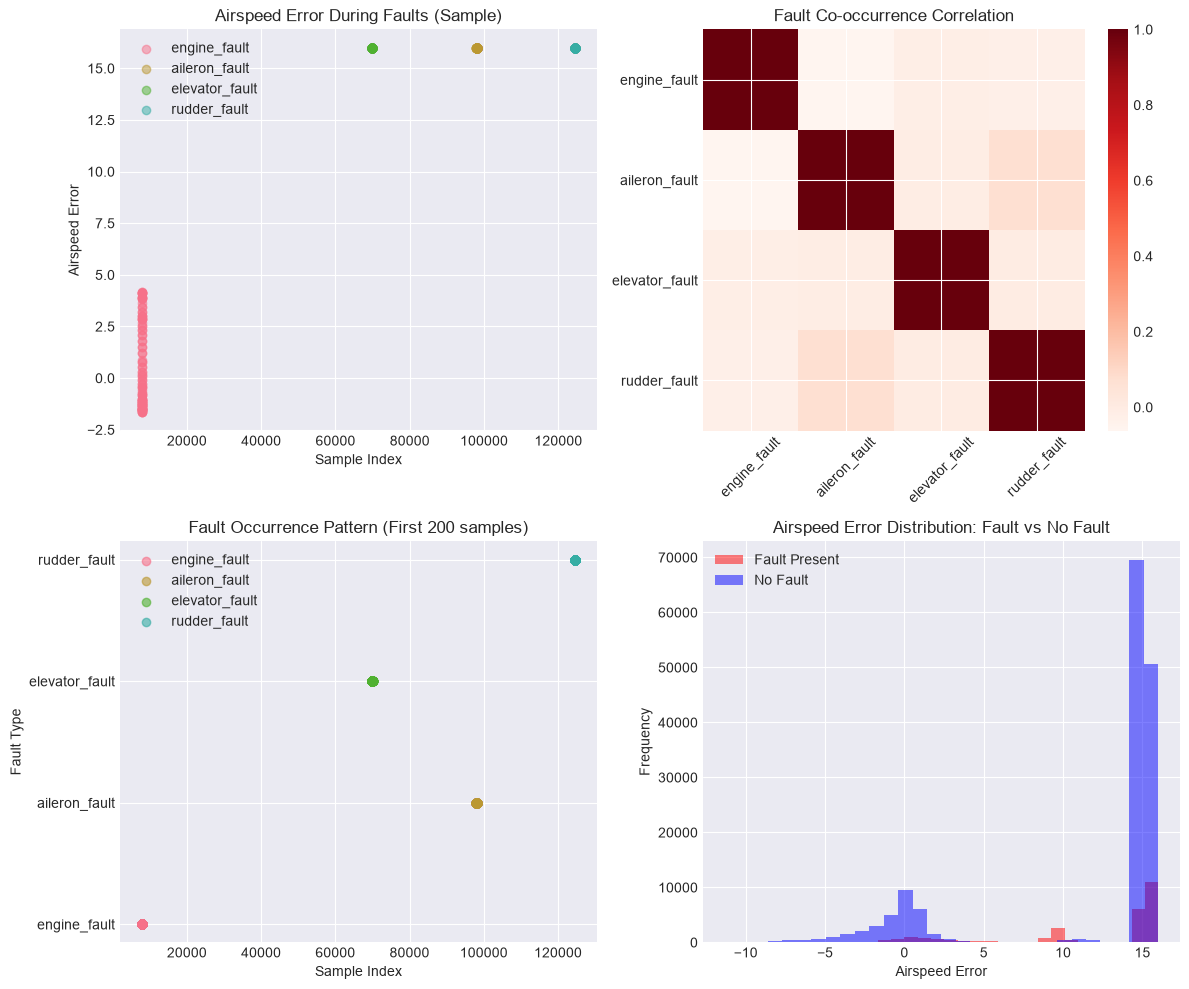

In [9]:
# Task 5: Analyze fault flags and their associations
print("=== FAULT FLAG ANALYSIS ===\n")

# Calculate fault statistics
print("Fault Flag Statistics:")
fault_stats = pd.DataFrame({
    'Total Faults': df[fault_cols].sum(),
    'Percentage': (df[fault_cols].sum() / len(df) * 100).round(2)
})
print(fault_stats)

# Analyze simultaneous faults
print("\nSimultaneous Fault Analysis:")
df['total_faults'] = df[fault_cols].sum(axis=1)
simultaneous_faults = df['total_faults'].value_counts().sort_index()
print(simultaneous_faults)

# Analyze fault correlations with error metrics
print("\nCorrelation Between Faults and Error Metrics:")
fault_error_corr = pd.DataFrame()
for fault in fault_cols:
    for error in error_cols:
        corr = df[df[fault] == 1][error].mean() - df[df[fault] == 0][error].mean()
        fault_error_corr.loc[fault, error] = round(corr, 4)
        
print("Mean Error Difference (Fault=1 vs Fault=0):")
print(fault_error_corr)

# Visualize fault patterns
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

# Plot 1: Fault distribution by error magnitude
for i, fault in enumerate(fault_cols):
    fault_data = df[df[fault] == 1]
    no_fault_data = df[df[fault] == 0]
    
    axes[0].scatter(fault_data.index[:100], fault_data['airspeed_error'].values[:100], 
                   alpha=0.5, label=f'{fault}')
    
axes[0].set_title('Airspeed Error During Faults (Sample)')
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('Airspeed Error')
axes[0].legend()

# Plot 2: Fault co-occurrence heatmap
fault_corr = df[fault_cols].corr()
im = axes[1].imshow(fault_corr, cmap='Reds', aspect='auto')
axes[1].set_title('Fault Co-occurrence Correlation')
axes[1].set_xticks(range(len(fault_cols)))
axes[1].set_xticklabels(fault_cols, rotation=45)
axes[1].set_yticks(range(len(fault_cols)))
axes[1].set_yticklabels(fault_cols)
plt.colorbar(im, ax=axes[1])

# Plot 3: Fault timing patterns
fault_indices = {}
for fault in fault_cols:
    fault_indices[fault] = df[df[fault] == 1].index.tolist()

for fault, indices in fault_indices.items():
    if indices:
        axes[2].scatter(indices[:200], [fault]*len(indices[:200]), alpha=0.6, label=fault)

axes[2].set_title('Fault Occurrence Pattern (First 200 samples)')
axes[2].set_xlabel('Sample Index')
axes[2].set_ylabel('Fault Type')
axes[2].legend()

# Plot 4: Error distribution comparison with/without faults
fault_present = df[df[fault_cols].sum(axis=1) > 0]
no_fault = df[df[fault_cols].sum(axis=1) == 0]

axes[3].hist(fault_present['airspeed_error'].dropna(), bins=30, alpha=0.5, label='Fault Present', color='red')
axes[3].hist(no_fault['airspeed_error'].dropna(), bins=30, alpha=0.5, label='No Fault', color='blue')
axes[3].set_title('Airspeed Error Distribution: Fault vs No Fault')
axes[3].set_xlabel('Airspeed Error')
axes[3].set_ylabel('Frequency')
axes[3].legend()

plt.tight_layout()
plt.show()

=== FAULT DURATION (RUN-LENGTH) ANALYSIS ===

engine_fault: 24 distinct fault episodes, median duration = 346 samples, max duration = 5385 samples
aileron_fault: 4 distinct fault episodes, median duration = 738 samples, max duration = 1379 samples
elevator_fault: 2 distinct fault episodes, median duration = 226 samples, max duration = 241 samples
rudder_fault: 1 distinct fault episodes, median duration = 523 samples, max duration = 523 samples


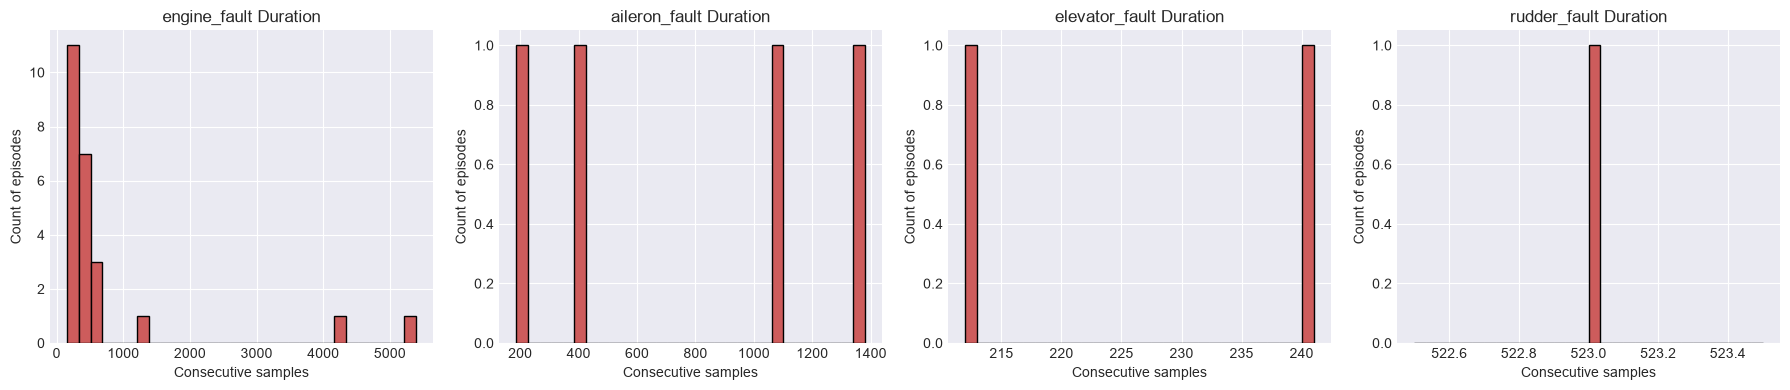

In [10]:
# Extra analysis + visualization: Fault duration (run-length) analysis
# WHY: knowing a fault occurred is less useful than knowing how long it lasts. A fault
# flag that flickers on for a single sample behaves very differently (sensor noise/glitch)
# than one that stays on for hundreds of samples (a real sustained failure). This changes
# how you'd design detection or recovery logic.
print("=== FAULT DURATION (RUN-LENGTH) ANALYSIS ===\n")

def run_lengths(binary_series):
    """Return the lengths of consecutive runs of 1s in a 0/1 series."""
    arr = binary_series.values
    lengths = []
    count = 0
    for v in arr:
        if v == 1:
            count += 1
        else:
            if count > 0:
                lengths.append(count)
            count = 0
    if count > 0:
        lengths.append(count)
    return lengths

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, fault in enumerate(fault_cols):
    lengths = run_lengths(df[fault])
    if lengths:
        axes[i].hist(lengths, bins=min(30, max(lengths)), color='indianred', edgecolor='black')
        print(f"{fault}: {len(lengths)} distinct fault episodes, "
              f"median duration = {np.median(lengths):.0f} samples, "
              f"max duration = {max(lengths)} samples")
    else:
        print(f"{fault}: no fault episodes found")
    axes[i].set_title(f'{fault} Duration')
    axes[i].set_xlabel('Consecutive samples')
    axes[i].set_ylabel('Count of episodes')

plt.tight_layout()
plt.show()


=== CLUSTER ANALYSIS AND HIDDEN PATTERNS ===

Principal Component Analysis (PCA):
Explained variance ratio: [0.22702001 0.16778107]
Total explained variance: 39.48%

Determining optimal number of clusters...


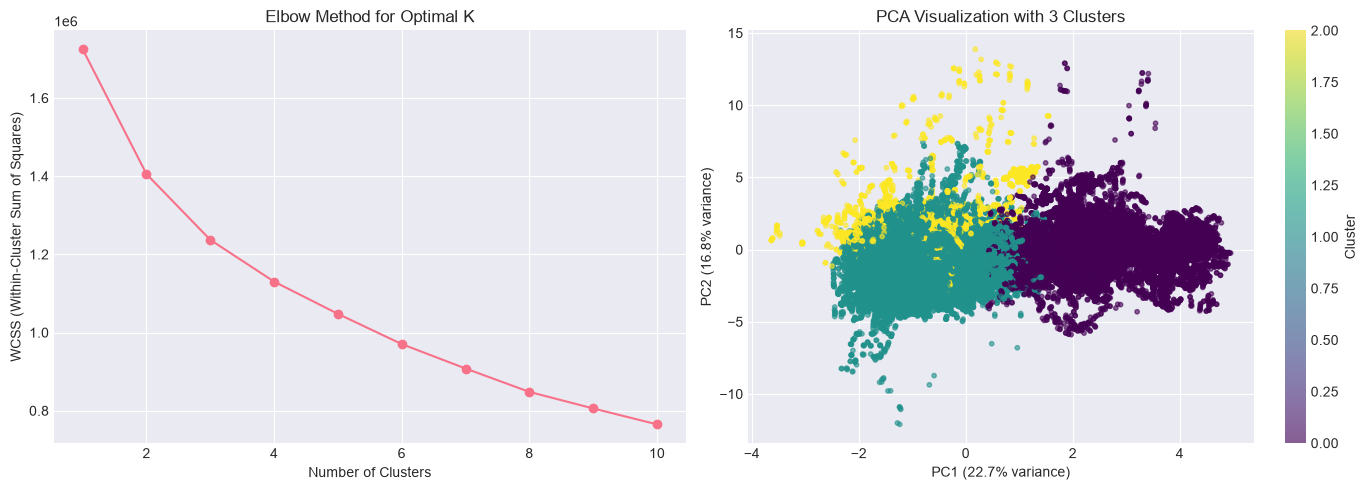


Cluster Distribution (K=3):
cluster
0    43935
1    88737
2    39808
Name: count, dtype: int64

Cluster Characteristics (Mean Values):
         airspeed_error  roll_error  pitch_error  yaw_error   vel_x  vel_y  \
cluster                                                                      
0                10.297      -0.906       -0.989    -52.190  14.190 -3.518   
1                11.165      -0.440       -0.475     23.796  -8.645  2.821   
2                14.752     -22.457       -2.192    246.274  -0.371 -0.573   

         vel_z  imu_x  imu_y  imu_z  
cluster                              
0       -0.067 -0.075  0.017  0.116  
1       -0.205 -0.006 -0.052 -0.882  
2        0.099 -0.013 -0.000 -0.880  


In [11]:
# Task 6: Identify clusters and hidden patterns
print("=== CLUSTER ANALYSIS AND HIDDEN PATTERNS ===\n")

# Prepare data for clustering
clustering_features = error_cols + ['vel_x', 'vel_y', 'vel_z', 'imu_x', 'imu_y', 'imu_z']
clustering_data = df[clustering_features].dropna()

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(clustering_data)

# PCA for dimensionality reduction
print("Principal Component Analysis (PCA):")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {sum(pca.explained_variance_ratio_):.2%}")

# Determine optimal number of clusters using elbow method
print("\nDetermining optimal number of clusters...")
wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

# Plot elbow curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cluster_range, wcss, marker='o', linestyle='-')
axes[0].set_title('Elbow Method for Optimal K')
axes[0].set_xlabel('Number of Clusters')
axes[0].set_ylabel('WCSS (Within-Cluster Sum of Squares)')

# Apply K-means clustering with optimal k (using 3 based on elbow)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(scaled_data)
df_clustered = clustering_data.copy()
df_clustered['cluster'] = cluster_labels

# Plot PCA results with clusters
scatter = axes[1].scatter(pca_result[:, 0], pca_result[:, 1], 
                         c=cluster_labels, cmap='viridis', alpha=0.6, s=10)
axes[1].set_title(f'PCA Visualization with {optimal_k} Clusters')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.colorbar(scatter, ax=axes[1], label='Cluster')

plt.tight_layout()
plt.show()

# Analyze cluster characteristics
print(f"\nCluster Distribution (K={optimal_k}):")
print(df_clustered['cluster'].value_counts().sort_index())

# Calculate cluster statistics
print("\nCluster Characteristics (Mean Values):")
cluster_stats = df_clustered.groupby('cluster').mean()
print(cluster_stats.round(3))

=== CLUSTER PROFILE INTERPRETATION ===



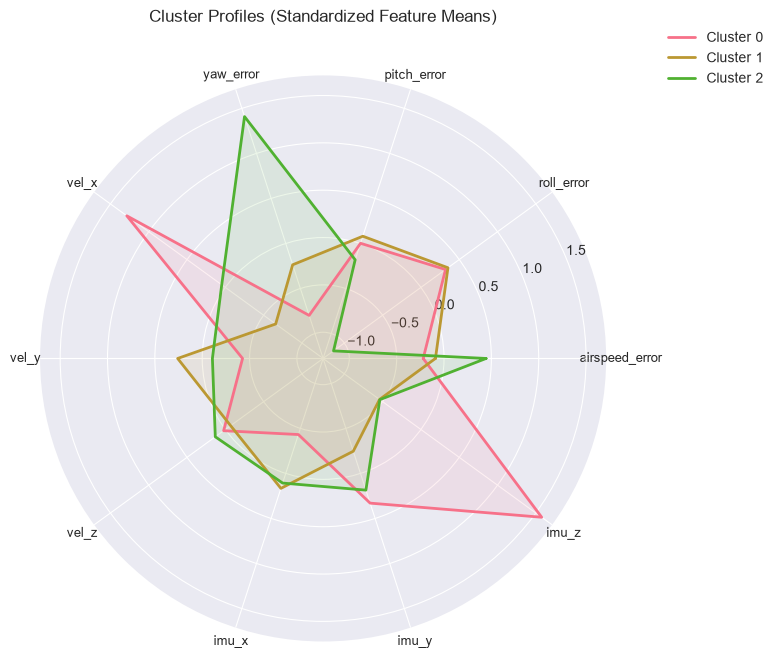

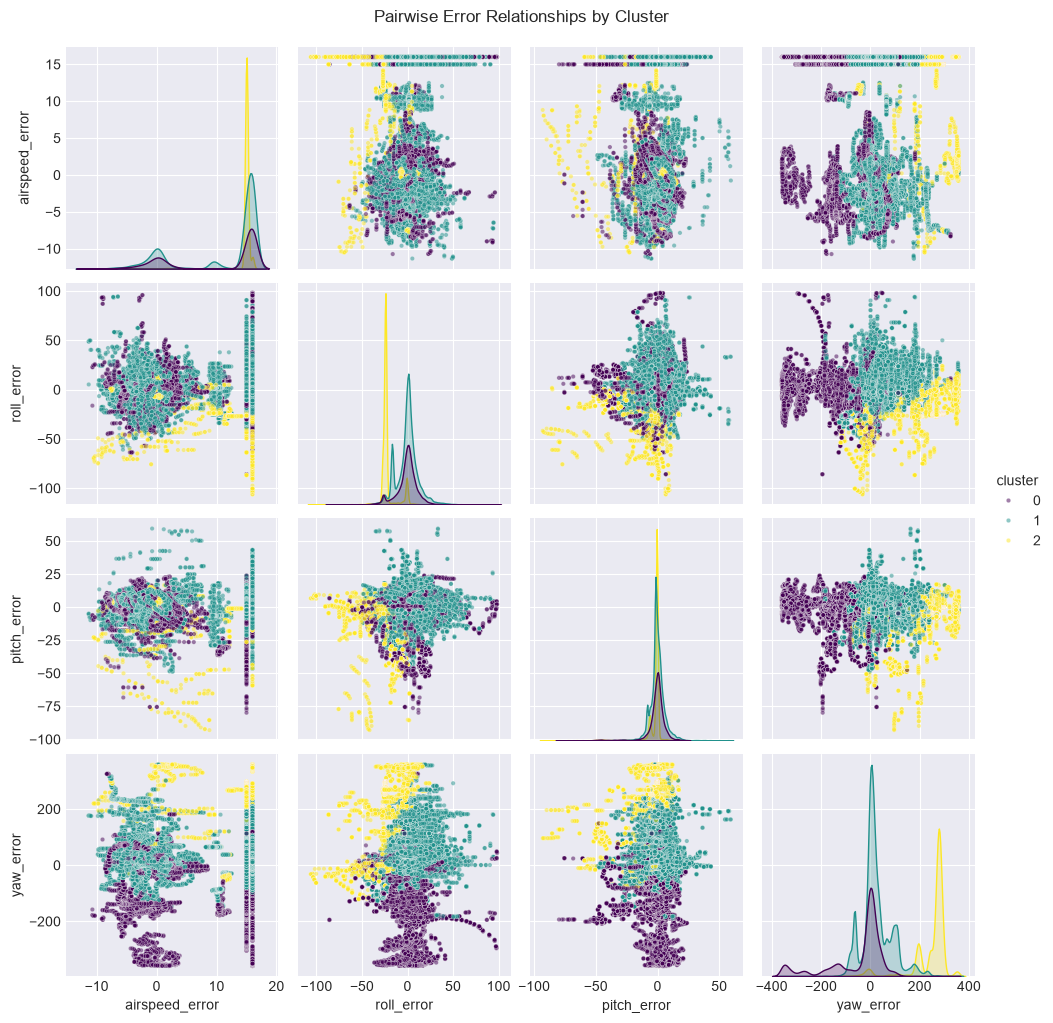

In [ ]:
print("=== CLUSTER PROFILE INTERPRETATION ===\n")

# Radar chart of standardized cluster means
cluster_means_scaled = pd.DataFrame(scaled_data, columns=clustering_features)
cluster_means_scaled['cluster'] = cluster_labels
radar_data = cluster_means_scaled.groupby('cluster').mean()

categories = list(radar_data.columns)
n_cats = len(categories)
angles = [n / float(n_cats) * 2 * np.pi for n in range(n_cats)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for cluster_id in radar_data.index:
    values = radar_data.loc[cluster_id].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=f'Cluster {cluster_id}')
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9)
ax.set_title('Cluster Profiles (Standardized Feature Means)', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# Pairwise scatter matrix of error columns, colored by cluster
plot_df = clustering_data[error_cols].copy()
plot_df['cluster'] = cluster_labels
sns.pairplot(plot_df, hue='cluster', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.5, 's': 10})
plt.suptitle('Pairwise Error Relationships by Cluster', y=1.02)
plt.show()


=== ADVANCED PATTERN DISCOVERY ===

1. Temporal Error Patterns:


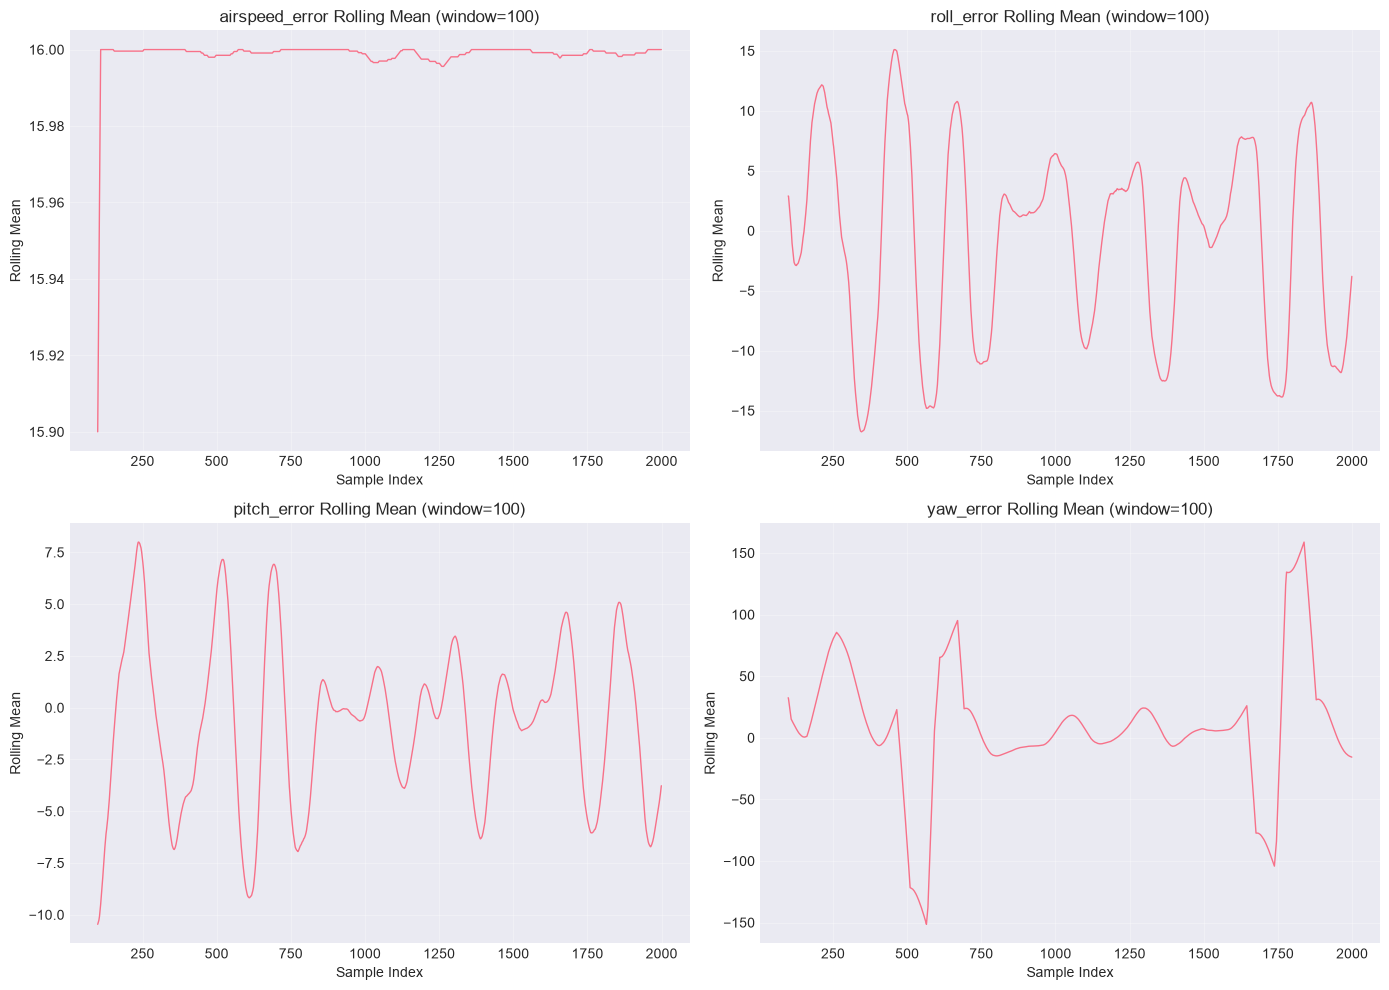


2. Cross-correlation Analysis Between Key Metrics:


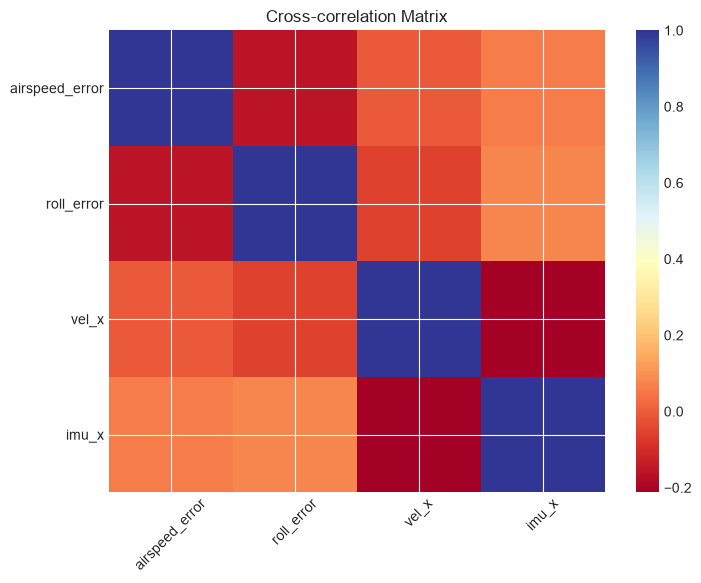


Strong Correlations (|r| > 0.5):

3. Statistical Anomaly Detection:
  airspeed_error: 290 anomalies detected (z-score > 3)
  roll_error: 1407 anomalies detected (z-score > 3)
  pitch_error: 2956 anomalies detected (z-score > 3)
  yaw_error: 2111 anomalies detected (z-score > 3)


In [13]:
# Advanced pattern discovery
print("=== ADVANCED PATTERN DISCOVERY ===\n")

# 1. Temporal patterns in errors
print("1. Temporal Error Patterns:")
window_size = 100
rolling_errors = df[error_cols].rolling(window=window_size).mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, error_col in enumerate(error_cols):
    axes[i].plot(rolling_errors[error_col].values[:2000], linewidth=1)
    axes[i].set_title(f'{error_col} Rolling Mean (window={window_size})')
    axes[i].set_xlabel('Sample Index')
    axes[i].set_ylabel('Rolling Mean')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Cross-correlation analysis
print("\n2. Cross-correlation Analysis Between Key Metrics:")
key_metrics = ['airspeed_error', 'roll_error', 'vel_x', 'imu_x']
cross_corr = df[key_metrics].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cross_corr, cmap='RdYlBu', aspect='auto')
ax.set_title('Cross-correlation Matrix')
ax.set_xticks(range(len(key_metrics)))
ax.set_xticklabels(key_metrics, rotation=45)
ax.set_yticks(range(len(key_metrics)))
ax.set_yticklabels(key_metrics)
plt.colorbar(im, ax=ax)
plt.show()

print("\nStrong Correlations (|r| > 0.5):")
for i in range(len(key_metrics)):
    for j in range(i+1, len(key_metrics)):
        corr_val = cross_corr.iloc[i, j]
        if abs(corr_val) > 0.5:
            print(f"  {key_metrics[i]} ↔ {key_metrics[j]}: {corr_val:.3f}")

# 3. Anomaly detection using statistical methods
print("\n3. Statistical Anomaly Detection:")
for error_col in error_cols:
    data = df[error_col].dropna()
    z_scores = np.abs(stats.zscore(data))
    anomalies = np.sum(z_scores > 3)
    print(f"  {error_col}: {anomalies} anomalies detected (z-score > 3)")

=== AUTOCORRELATION OF ERROR SIGNALS ===



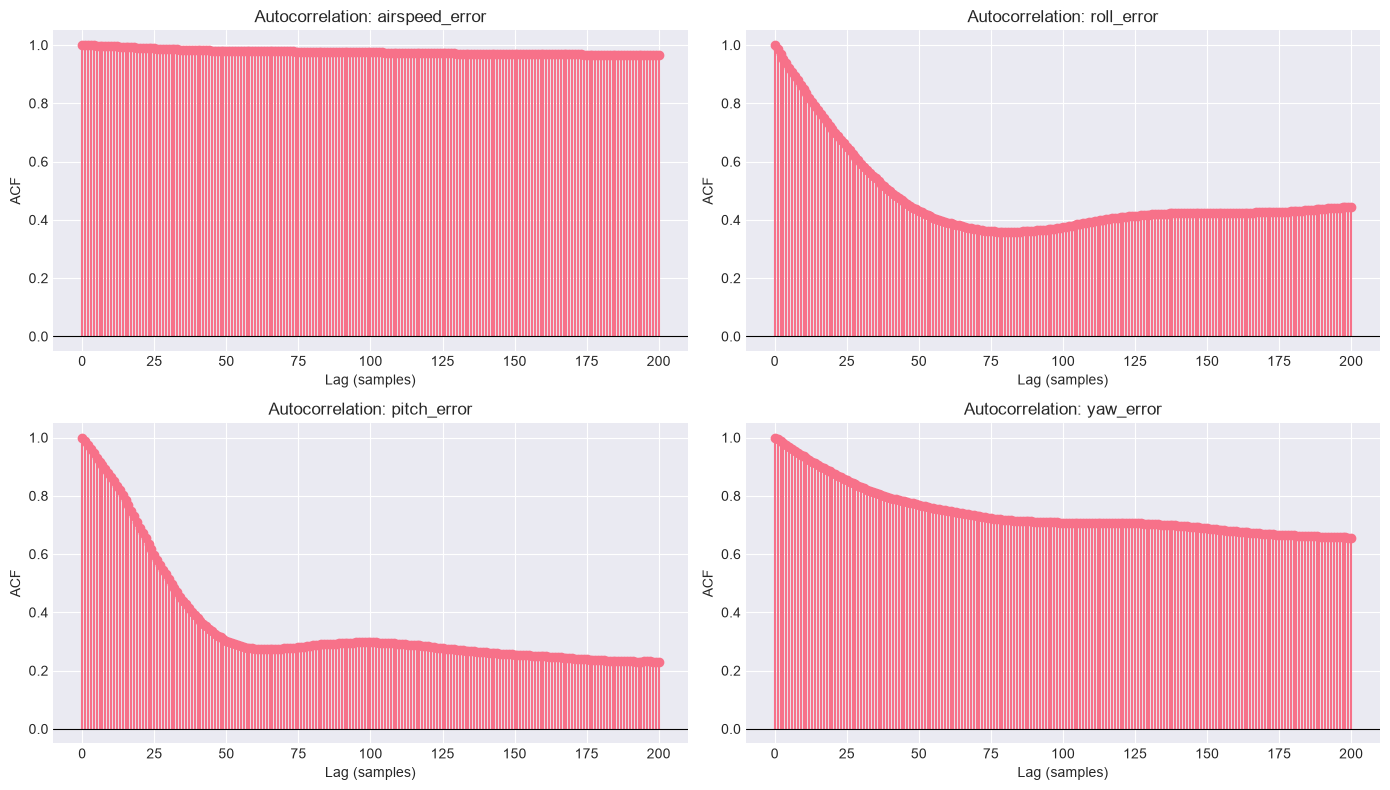

Interpretation guide:
  - ACF decaying slowly -> long-memory drift, errors are highly autocorrelated.
  - ACF dropping to ~0 quickly -> errors behave close to random noise sample-to-sample.
  - Periodic bumps in ACF -> a cyclical/oscillatory component in the error.


In [14]:
# Extra visualization: Autocorrelation (ACF) of error signals
# WHY: the rolling-mean plot shows *a* trend, but doesn't quantify how long errors stay
# correlated with themselves over time. Autocorrelation answers: "if the error is high now,
# how many samples ahead is it still likely to be high?" This matters for descriptive mining
# because strong autocorrelation means the errors are NOT independent samples (important
# caveat for any later statistical test that assumes i.i.d. data), and it also tells us the
# natural time scale of whatever process is driving the error (fast noise vs slow drift).
print("=== AUTOCORRELATION OF ERROR SIGNALS ===\n")

def autocorrelation(series, max_lag=200):
    series = series.dropna().values
    series = series - series.mean()
    acf_vals = []
    denom = np.dot(series, series)
    for lag in range(max_lag + 1):
        if lag == 0:
            acf_vals.append(1.0)
        else:
            num = np.dot(series[:-lag], series[lag:])
            acf_vals.append(num / denom if denom != 0 else 0.0)
    return acf_vals

max_lag = 200
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(error_cols):
    acf_vals = autocorrelation(df[col], max_lag=max_lag)
    axes[i].stem(range(max_lag + 1), acf_vals, basefmt=' ')
    axes[i].axhline(0, color='black', linewidth=0.8)
    axes[i].set_title(f'Autocorrelation: {col}')
    axes[i].set_xlabel('Lag (samples)')
    axes[i].set_ylabel('ACF')

plt.tight_layout()
plt.show()

print("Interpretation guide:")
print("  - ACF decaying slowly -> long-memory drift, errors are highly autocorrelated.")
print("  - ACF dropping to ~0 quickly -> errors behave close to random noise sample-to-sample.")
print("  - Periodic bumps in ACF -> a cyclical/oscillatory component in the error.")
